
# TFG - Notebook de resultados

Este notebook genera los resultados empíricos del TFG sobre **valoración por simulación de una call americana con dividendos bajo volatilidad con cambio de régimen**.

La idea del notebook es sencilla:

1. **calibrar la volatilidad con un índice real** (VIX),
2. separar la muestra en **régimen bajo** y **régimen alto** con un criterio transparente,
3. estimar las volatilidades medias por régimen y la matriz de transición empírica,
4. construir los resultados del capítulo 4:
   - validación con **CRR**,
   - comparación **LSMC vs LSMC+IS**,
   - escenario **OTM**,
   - sensibilidad de $\theta$,
   - convergencia y coste,
   - sensibilidad a $r$ y $q$.




## 1. Librerías y configuración

El notebook trabaja con un CSV local del VIX para que la ejecución sea reproducible y no dependa de descargar datos online en el momento de la corrección.


In [40]:

import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")

BASE_DIR = Path(".")
DATA_PATH = BASE_DIR / "vix_fred.csv"
OUTPUT_DIR = BASE_DIR / "outputs_tfg"
OUTPUT_DIR.mkdir(exist_ok=True)

SEED = 123



## 2. Carga del VIX y construcción de regímenes

Se usa una serie del **VIX** guardada en local. El criterio de separación entre régimen bajo y alto: la **mediana** de la muestra.

- Si \($VIX_t \leq \text{mediana}$\), se considera **régimen 1 (bajo)**.
- Si \($VIX_t > \text{mediana}$\), se considera **régimen 2 (alto)**.



In [41]:

vix = pd.read_csv(DATA_PATH, parse_dates=["DATE"]).sort_values("DATE").reset_index(drop=True)

threshold = vix["VIX"].median()
vix["state"] = np.where(vix["VIX"] <= threshold, 1, 2)

sigma_low = vix.loc[vix["state"] == 1, "VIX"].mean() / 100
sigma_high = vix.loc[vix["state"] == 2, "VIX"].mean() / 100
sigma_const = vix["VIX"].mean() / 100

transition_counts = np.zeros((2, 2), dtype=int)
states = vix["state"].to_numpy()

for a, b in zip(states[:-1], states[1:]):
    transition_counts[a - 1, b - 1] += 1

P = transition_counts / transition_counts.sum(axis=1, keepdims=True)
init_state = int(vix["state"].iloc[-1])

calibration_table = pd.DataFrame({
    "Magnitud": [
        "Tamaño de muestra",
        "Mediana VIX usada como umbral",
        "sigma_L",
        "sigma_H",
        "sigma_constante (media muestral)",
        "Estado inicial para simulación"
    ],
    "Valor": [
        len(vix),
        threshold,
        sigma_low,
        sigma_high,
        sigma_const,
        init_state
    ]
})

display(vix.head())
display(calibration_table)
print("Matriz de transición empírica:")
print(P)


,DATE,VIX,state
0,1990-01-02,17.2400,1
1,1990-01-03,18.1900,2
2,1990-01-04,19.2200,2
3,1990-01-05,20.1100,2
4,1990-01-08,20.2600,2


,Magnitud,Valor
0,Tamaño de muestra,9156.0000
1,Mediana VIX usada como umbral,17.6100
2,sigma_L,0.1404
3,sigma_H,0.2489
4,sigma_constante (media muestral),0.1946
5,Estado inicial para simulación,2.0000


Matriz de transición empírica:
[[0.94830971 0.05169029]
 [0.05164114 0.94835886]]


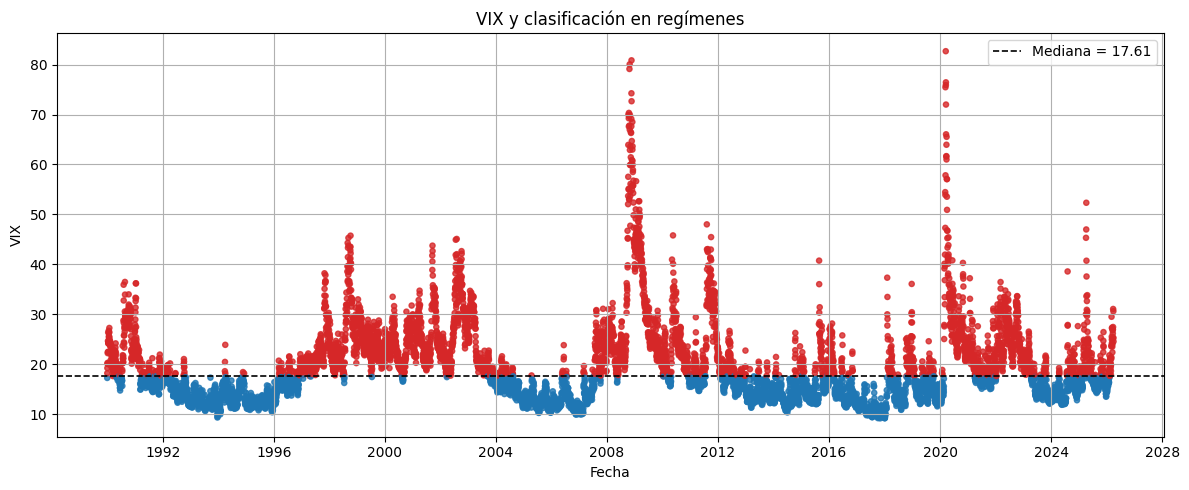

In [42]:

fig, ax = plt.subplots(figsize=(12, 5))
colors = vix["state"].map({1: "tab:blue", 2: "tab:red"})
ax.scatter(vix["DATE"], vix["VIX"], c=colors, s=14, alpha=0.8)
ax.axhline(threshold, color="black", linestyle="--", linewidth=1.2, label=f"Mediana = {threshold:0.2f}")
ax.set_title("VIX y clasificación en regímenes")
ax.set_xlabel("Fecha")
ax.set_ylabel("VIX")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "vix_regimenes.png", dpi=200, bbox_inches="tight")
plt.show()



## 3. Funciones auxiliares

Se presentan las funciones de simulación y valoración.

### Notas de implementación
- En LSMC uso una base Laguerre sencilla de grado 2 sobre \($S_t / K$\).
- En el caso con cambio de régimen hago regresiones separadas por régimen.
- En Importance Sampling desplazo la media de las innovaciones gaussianas y corrijo con el *likelihood ratio*.


In [43]:

def laguerre_basis(x):
    return np.column_stack([
        np.ones_like(x),
        1.0 - x,
        1.0 - 2.0 * x + 0.5 * x**2
    ])


def format_ci(low, high):
    return f"[{low:0.4f}, {high:0.4f}]"


def export_table(df, filename):
    df.to_latex(OUTPUT_DIR / filename, index=False, escape=False, float_format="%.4f")


def american_call_crr(S0, K, T, r, q, sigma, N):
    dt = T / N
    u = math.exp(sigma * math.sqrt(dt))
    d = 1.0 / u
    p = (math.exp((r - q) * dt) - d) / (u - d)
    disc = math.exp(-r * dt)

    if not (0 < p < 1):
        raise ValueError("La probabilidad neutral al riesgo ha salido fuera de (0,1).")

    prices = np.array([S0 * (u ** j) * (d ** (N - j)) for j in range(N + 1)])
    values = np.maximum(prices - K, 0.0)

    for n in range(N - 1, -1, -1):
        prices = prices[:-1] / d
        continuation = disc * (p * values[1:] + (1 - p) * values[:-1])
        exercise = np.maximum(prices - K, 0.0)
        values = np.maximum(exercise, continuation)

    return float(values[0])


def simulate_constant_paths(S0, T, r, q, sigma, N, M, theta=0.0, seed=123):
    rng = np.random.default_rng(seed)
    dt = T / N
    sqrt_dt = math.sqrt(dt)

    S = np.empty((M, N + 1))
    logL = np.zeros((M, N + 1))
    S[:, 0] = S0

    for n in range(N):
        z = rng.normal(loc=theta, scale=1.0, size=M)
        S[:, n + 1] = S[:, n] * np.exp((r - q - 0.5 * sigma**2) * dt + sigma * sqrt_dt * z)
        logL[:, n + 1] = logL[:, n] + (-theta * z + 0.5 * theta**2)

    return S, logL


def simulate_regime_paths(S0, T, r, q, sigmas, P, N, M, init_state=1, theta=0.0, seed=123):
    rng = np.random.default_rng(seed)
    dt = T / N
    sqrt_dt = math.sqrt(dt)

    S = np.empty((M, N + 1))
    X = np.empty((M, N + 1), dtype=np.int8)
    logL = np.zeros((M, N + 1))

    S[:, 0] = S0
    X[:, 0] = init_state

    for n in range(N):
        u = rng.random(M)
        p_to_state_1 = np.where(X[:, n] == 1, P[0, 0], P[1, 0])
        X[:, n + 1] = np.where(u <= p_to_state_1, 1, 2)

        sigma_n = np.where(X[:, n] == 1, sigmas[0], sigmas[1])
        z = rng.normal(loc=theta, scale=1.0, size=M)

        S[:, n + 1] = S[:, n] * np.exp((r - q - 0.5 * sigma_n**2) * dt + sigma_n * sqrt_dt * z)
        logL[:, n + 1] = logL[:, n] + (-theta * z + 0.5 * theta**2)

    return S, X, logL


def lsmc_american_call_constant(S, K, r, T, logL=None, min_itm=30):
    M, N1 = S.shape
    N = N1 - 1
    dt = T / N

    if logL is None:
        logL = np.zeros_like(S)

    intrinsic = np.maximum(S - K, 0.0)
    cashflow = intrinsic[:, -1].copy()
    exercise_time = np.full(M, N, dtype=int)

    for n in range(N - 1, 0, -1):
        mask = (intrinsic[:, n] > 0) & (exercise_time > n)
        idx = np.where(mask)[0]

        if len(idx) < min_itm:
            continue

        x = S[idx, n] / K
        y = cashflow[idx] * np.exp(-r * dt * (exercise_time[idx] - n))
        rel_weight = np.exp(logL[idx, exercise_time[idx]] - logL[idx, n])
        y_adj = y * rel_weight

        B = laguerre_basis(x)
        beta, *_ = np.linalg.lstsq(B, y_adj, rcond=None)

        continuation = B @ beta
        exercise = intrinsic[idx, n]

        exercise_now = exercise >= continuation
        ex_idx = idx[exercise_now]

        cashflow[ex_idx] = intrinsic[ex_idx, n]
        exercise_time[ex_idx] = n

    path_values = cashflow * np.exp(-r * dt * exercise_time) * np.exp(logL[np.arange(M), exercise_time])
    price = path_values.mean()
    se = path_values.std(ddof=1) / np.sqrt(M)

    return {
        "price": float(price),
        "se": float(se),
        "ci_low": float(price - 1.96 * se),
        "ci_high": float(price + 1.96 * se),
        "path_values": path_values,
        "exercise_time": exercise_time
    }


def lsmc_american_call_regime(S, X, K, r, T, logL=None, min_itm=30):
    M, N1 = S.shape
    N = N1 - 1
    dt = T / N

    if logL is None:
        logL = np.zeros_like(S)

    intrinsic = np.maximum(S - K, 0.0)
    cashflow = intrinsic[:, -1].copy()
    exercise_time = np.full(M, N, dtype=int)

    for n in range(N - 1, 0, -1):
        alive_now = exercise_time > n

        for regime in (1, 2):
            mask = alive_now & (X[:, n] == regime) & (intrinsic[:, n] > 0)
            idx = np.where(mask)[0]

            if len(idx) < min_itm:
                continue

            x = S[idx, n] / K
            y = cashflow[idx] * np.exp(-r * dt * (exercise_time[idx] - n))
            rel_weight = np.exp(logL[idx, exercise_time[idx]] - logL[idx, n])
            y_adj = y * rel_weight

            B = laguerre_basis(x)
            beta, *_ = np.linalg.lstsq(B, y_adj, rcond=None)

            continuation = B @ beta
            exercise = intrinsic[idx, n]

            exercise_now = exercise >= continuation
            ex_idx = idx[exercise_now]

            cashflow[ex_idx] = intrinsic[ex_idx, n]
            exercise_time[ex_idx] = n

    path_values = cashflow * np.exp(-r * dt * exercise_time) * np.exp(logL[np.arange(M), exercise_time])
    price = path_values.mean()
    se = path_values.std(ddof=1) / np.sqrt(M)

    return {
        "price": float(price),
        "se": float(se),
        "ci_low": float(price - 1.96 * se),
        "ci_high": float(price + 1.96 * se),
        "path_values": path_values,
        "exercise_time": exercise_time
    }


def run_case_constant(S0, K, T, r, q, sigma, N, M, theta=0.0, seed=123):
    t0 = time.perf_counter()
    S, logL = simulate_constant_paths(S0, T, r, q, sigma, N, M, theta=theta, seed=seed)
    out = lsmc_american_call_constant(S, K, r, T, logL=logL)
    elapsed = time.perf_counter() - t0

    out["time"] = elapsed
    out["efficiency"] = 1.0 / (out["se"]**2 * elapsed)

    return out


def run_case_regime(S0, K, T, r, q, sigmas, P, N, M, init_state, theta=0.0, seed=123):
    t0 = time.perf_counter()
    S, X, logL = simulate_regime_paths(
        S0=S0, T=T, r=r, q=q, sigmas=sigmas, P=P,
        N=N, M=M, init_state=init_state, theta=theta, seed=seed
    )
    out = lsmc_american_call_regime(S, X, K, r, T, logL=logL)
    elapsed = time.perf_counter() - t0

    out["time"] = elapsed
    out["efficiency"] = 1.0 / (out["se"]**2 * elapsed)

    return out



## 4. Validación con árbol binomial

Para validar la lógica de ejercicio anticipado, primero trabajo en un caso de volatilidad constante. En vez de inventar \(\sigma\), la tomo como la **media muestral del VIX** de la muestra cargada en el notebook.

Parámetros del caso de validación:
- \($S_0$ = 40\)
- \($K$ = 40\)
- \($T$ = 1\)
- \($r$ = 0.06\)
- \($q$ = 0.02\)
- \($\sigma$ = $\bar{VIX}$/100\)


In [44]:

S0_val, K_val, T_val = 40, 40, 1
r_val, q_val = 0.06, 0.02
N_crr, N_lsmc, M_val = 500, 50, 30000

price_crr = american_call_crr(S0_val, K_val, T_val, r_val, q_val, sigma_const, N_crr)
res_val_lsmc = run_case_constant(S0_val, K_val, T_val, r_val, q_val, sigma_const, N_lsmc, M_val, theta=0.0, seed=SEED)

table_42 = pd.DataFrame([
    {
        "Método": f"CRR (N={N_crr})",
        "Precio": price_crr,
        "SE": np.nan,
        "IC 95 %": "—",
        "Tiempo (s)": np.nan,
        "Eficiencia": np.nan
    },
    {
        "Método": "LSMC",
        "Precio": res_val_lsmc["price"],
        "SE": res_val_lsmc["se"],
        "IC 95 %": format_ci(res_val_lsmc["ci_low"], res_val_lsmc["ci_high"]),
        "Tiempo (s)": res_val_lsmc["time"],
        "Eficiencia": res_val_lsmc["efficiency"] / 1000
    }
])

display(table_42)
export_table(table_42, "tabla_42_validacion.tex")


,Método,Precio,SE,IC 95 %,Tiempo (s),Eficiencia
0,CRR (N=500),3.8087,NaN,—,NaN,NaN
1,LSMC,3.8381,0.0315,"[3.7765, 3.8998]",0.0897,11.2622



## 5. Cambio de régimen: LSMC frente a LSMC+IS

Ahora paso al caso central del TFG. Las volatilidades y la matriz de transición salen de la calibración empírica anterior.

En el caso con Importance Sampling, después de varias pruebas sencillas, tomo **$\theta = 0.1$** para el escenario base. No es una elección teóricamente óptima; simplemente funciona de forma estable y mejora claramente la precisión.


In [45]:

S0_base, K_base, T_base = 40, 40, 1
r_base, q_base = 0.06, 0.02
N_base, M_base = 50, 30000

res_base_lsmc = run_case_regime(
    S0=S0_base, K=K_base, T=T_base, r=r_base, q=q_base,
    sigmas=(sigma_low, sigma_high), P=P, N=N_base, M=M_base,
    init_state=init_state, theta=0.0, seed=SEED
)

res_base_is = run_case_regime(
    S0=S0_base, K=K_base, T=T_base, r=r_base, q=q_base,
    sigmas=(sigma_low, sigma_high), P=P, N=N_base, M=M_base,
    init_state=init_state, theta=0.1, seed=SEED
)

table_43 = pd.DataFrame([
    {
        "Método": "LSMC",
        "Precio": res_base_lsmc["price"],
        "SE": res_base_lsmc["se"],
        "IC 95 %": format_ci(res_base_lsmc["ci_low"], res_base_lsmc["ci_high"]),
        "Tiempo (s)": res_base_lsmc["time"],
        "Eficiencia": res_base_lsmc["efficiency"] / 1000
    },
    {
        "Método": "LSMC+IS (θ = 0.1)",
        "Precio": res_base_is["price"],
        "SE": res_base_is["se"],
        "IC 95 %": format_ci(res_base_is["ci_low"], res_base_is["ci_high"]),
        "Tiempo (s)": res_base_is["time"],
        "Eficiencia": res_base_is["efficiency"] / 1000
    }
])

display(table_43)
export_table(table_43, "tabla_43_regimen.tex")


,Método,Precio,SE,IC 95 %,Tiempo (s),Eficiencia
0,LSMC,4.0886,0.0322,"[4.0254, 4.1517]",0.1402,6.8759
1,LSMC+IS (θ = 0.1),4.0531,0.0161,"[4.0215, 4.0846]",0.1327,29.0325



## 6. Escenario OTM

Aquí fuerzo un caso más exigente:
- \($S_0$ = 38\)
- \($K$ = 45\)
- \($T$ = 1\)
- \($N$ = 60\)

En este entorno, un sesgo moderado en IS funciona mejor. Después de probar varios valores, uso **\($\theta$ = 0.2\)** como valor base del caso OTM.


In [46]:

S0_otm, K_otm, T_otm = 38, 45, 1
r_otm, q_otm = 0.06, 0.02
N_otm, M_otm = 50, 30000

res_otm_lsmc = run_case_regime(
    S0=S0_otm, K=K_otm, T=T_otm, r=r_otm, q=q_otm,
    sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M_otm,
    init_state=init_state, theta=0.0, seed=SEED
)

res_otm_is = run_case_regime(
    S0=S0_otm, K=K_otm, T=T_otm, r=r_otm, q=q_otm,
    sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M_otm,
    init_state=init_state, theta=0.2, seed=SEED
)

table_44 = pd.DataFrame([
    {
        "Método": "LSMC",
        "Precio": res_otm_lsmc["price"],
        "SE": res_otm_lsmc["se"],
        "IC 95 %": format_ci(res_otm_lsmc["ci_low"], res_otm_lsmc["ci_high"]),
        "Tiempo (s)": res_otm_lsmc["time"],
        "Eficiencia": res_otm_lsmc["efficiency"] / 1000
    },
    {
        "Método": "LSMC+IS (θ = 0.2)",
        "Precio": res_otm_is["price"],
        "SE": res_otm_is["se"],
        "IC 95 %": format_ci(res_otm_is["ci_low"], res_otm_is["ci_high"]),
        "Tiempo (s)": res_otm_is["time"],
        "Eficiencia": res_otm_is["efficiency"] / 1000
    }
])

display(table_44)
export_table(table_44, "tabla_44_otm.tex")


,Método,Precio,SE,IC 95 %,Tiempo (s),Eficiencia
0,LSMC,1.4142,0.0196,"[1.3758, 1.4526]",0.0891,29.2661
1,LSMC+IS (θ = 0.2),1.3839,0.0067,"[1.3708, 1.3970]",0.1121,200.1737



## 7. Sensibilidad de $\theta$ en OTM

Repito el caso OTM variando $\theta$ para ver cómo cambia la precisión. No busco encontrar una “solución exacta”, sino ver si el mecanismo funciona de forma razonable.


In [47]:

theta_grid = [0.0, 0.1, 0.2, 0.3, 0.4]
theta_rows = []

for theta in theta_grid:
    res = run_case_regime(
        S0=S0_otm, K=K_otm, T=T_otm, r=r_otm, q=q_otm,
        sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M_otm,
        init_state=init_state, theta=theta, seed=SEED
    )

    theta_rows.append({
        "Método": f"LSMC+IS (θ = {theta:0.1f})" if theta > 0 else "LSMC (θ = 0.0)",
        "Precio": res["price"],
        "SE": res["se"],
        "IC 95 %": format_ci(res["ci_low"], res["ci_high"]),
        "Tiempo (s)": res["time"],
        "Eficiencia": res["efficiency"] / 1000
    })

table_45 = pd.DataFrame(theta_rows).sort_values("SE").reset_index(drop=True)
display(table_45)
export_table(table_45, "tabla_45_theta.tex")


,Método,Precio,SE,IC 95 %,Tiempo (s),Eficiencia
0,LSMC+IS (θ = 0.2),1.3839,0.0067,"[1.3708, 1.3970]",0.1088,206.2008
1,LSMC+IS (θ = 0.3),1.3621,0.0075,"[1.3474, 1.3767]",0.1186,150.5234
2,LSMC+IS (θ = 0.1),1.3949,0.0102,"[1.3750, 1.4149]",0.1029,93.8012
3,LSMC+IS (θ = 0.4),1.3028,0.0121,"[1.2790, 1.3265]",0.1305,52.1052
4,LSMC (θ = 0.0),1.4142,0.0196,"[1.3758, 1.4526]",0.0857,30.4164



## 8. Convergencia y coste computacional

Comparo ahora cómo evolucionan LSMC y LSMC+IS cuando aumenta el número de trayectorias $M$.


In [48]:

M_grid = [5000, 10000, 20000, 40000]
conv_rows = []

for M in M_grid:
    res_std = run_case_regime(
        S0=S0_otm, K=K_otm, T=T_otm, r=r_otm, q=q_otm,
        sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M,
        init_state=init_state, theta=0.0, seed=SEED
    )

    res_is = run_case_regime(
        S0=S0_otm, K=K_otm, T=T_otm, r=r_otm, q=q_otm,
        sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M,
        init_state=init_state, theta=0.2, seed=SEED
    )

    conv_rows.append({
        "Método": "LSMC",
        "M": M,
        "Precio": res_std["price"],
        "SE": res_std["se"],
        "Tiempo (s)": res_std["time"],
        "Eficiencia": res_std["efficiency"] / 1000
    })

    conv_rows.append({
        "Método": "LSMC+IS (θ = 0.2)",
        "M": M,
        "Precio": res_is["price"],
        "SE": res_is["se"],
        "Tiempo (s)": res_is["time"],
        "Eficiencia": res_is["efficiency"] / 1000
    })

table_46 = pd.DataFrame(conv_rows)
display(table_46)
export_table(table_46, "tabla_46_convergencia.tex")


,Método,M,Precio,SE,Tiempo (s),Eficiencia
0,LSMC,5000,1.4155,0.0502,0.0196,20.2918
1,LSMC+IS (θ = 0.2),5000,1.3795,0.0159,0.0228,172.6124
2,LSMC,10000,1.4349,0.0358,0.0296,26.4157
3,LSMC+IS (θ = 0.2),10000,1.4048,0.0115,0.0380,198.3664
4,LSMC,20000,1.3813,0.0241,0.0523,33.0723
5,LSMC+IS (θ = 0.2),20000,1.3939,0.0081,0.0673,228.8362
6,LSMC,40000,1.4233,0.0188,0.1115,25.4683
7,LSMC+IS (θ = 0.2),40000,1.3778,0.0056,0.1448,219.6161


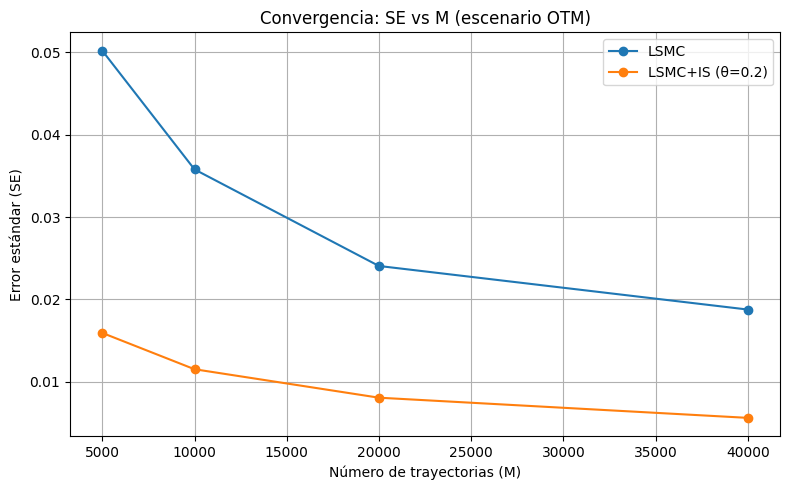

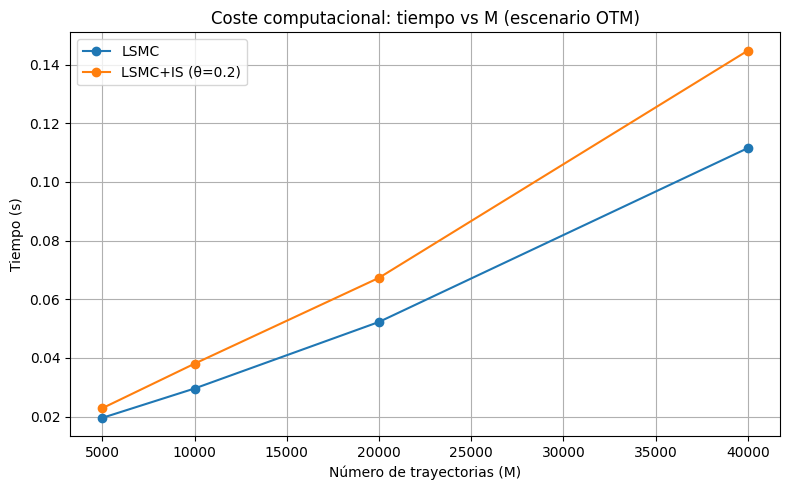

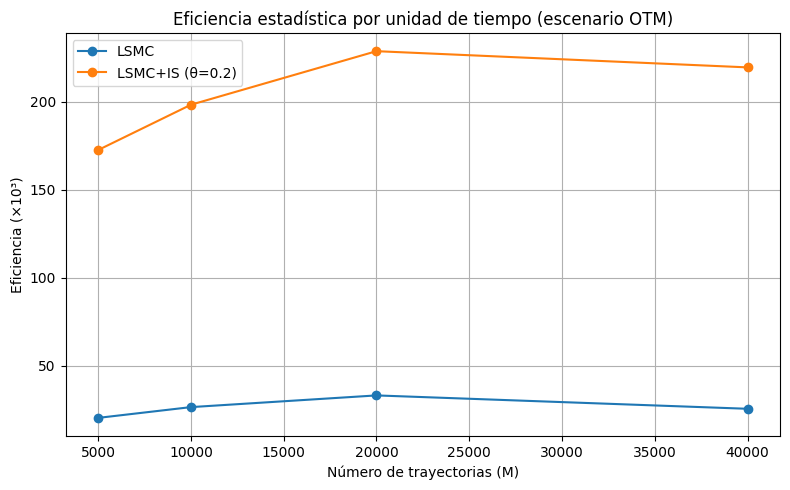

In [49]:

conv_std = table_46[table_46["Método"] == "LSMC"].copy()
conv_is = table_46[table_46["Método"] == "LSMC+IS (θ = 0.2)"].copy()

# Figura 4.1 - SE vs M
plt.figure(figsize=(8, 5))
plt.plot(conv_std["M"], conv_std["SE"], marker="o", label="LSMC")
plt.plot(conv_is["M"], conv_is["SE"], marker="o", label="LSMC+IS (θ=0.2)")
plt.title("Convergencia: SE vs M (escenario OTM)")
plt.xlabel("Número de trayectorias (M)")
plt.ylabel("Error estándar (SE)")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figura_41_se_vs_m.png", dpi=200, bbox_inches="tight")
plt.show()

# Figura 4.2 - Tiempo vs M
plt.figure(figsize=(8, 5))
plt.plot(conv_std["M"], conv_std["Tiempo (s)"], marker="o", label="LSMC")
plt.plot(conv_is["M"], conv_is["Tiempo (s)"], marker="o", label="LSMC+IS (θ=0.2)")
plt.title("Coste computacional: tiempo vs M (escenario OTM)")
plt.xlabel("Número de trayectorias (M)")
plt.ylabel("Tiempo (s)")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figura_42_tiempo_vs_m.png", dpi=200, bbox_inches="tight")
plt.show()

# Figura 4.3 - Eficiencia vs M
plt.figure(figsize=(8, 5))
plt.plot(conv_std["M"], conv_std["Eficiencia"], marker="o", label="LSMC")
plt.plot(conv_is["M"], conv_is["Eficiencia"], marker="o", label="LSMC+IS (θ=0.2)")
plt.title("Eficiencia estadística por unidad de tiempo (escenario OTM)")
plt.xlabel("Número de trayectorias (M)")
plt.ylabel("Eficiencia (×10³)")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figura_43_eficiencia_vs_m.png", dpi=200, bbox_inches="tight")
plt.show()



## 9. Sensibilidad a tipos de interés $r$

Mantengo el escenario OTM y varío $r$ para comprobar que el entorno numérico responde de forma financieramente razonable.


In [50]:

r_grid = [0.00, 0.02, 0.05, 0.08]
rows_r = []

for r_test in r_grid:
    res_std = run_case_regime(
        S0=S0_otm, K=K_otm, T=T_otm, r=r_test, q=q_otm,
        sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M_otm,
        init_state=init_state, theta=0.0, seed=SEED
    )

    res_is = run_case_regime(
        S0=S0_otm, K=K_otm, T=T_otm, r=r_test, q=q_otm,
        sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M_otm,
        init_state=init_state, theta=0.2, seed=SEED
    )

    rows_r.append({
        "r": r_test,
        "Método": "LSMC",
        "Precio": res_std["price"],
        "SE": res_std["se"],
        "IC 95 %": format_ci(res_std["ci_low"], res_std["ci_high"]),
        "Tiempo (s)": res_std["time"],
        "Eficiencia": res_std["efficiency"] / 1000
    })

    rows_r.append({
        "r": r_test,
        "Método": "LSMC+IS (θ = 0.2)",
        "Precio": res_is["price"],
        "SE": res_is["se"],
        "IC 95 %": format_ci(res_is["ci_low"], res_is["ci_high"]),
        "Tiempo (s)": res_is["time"],
        "Eficiencia": res_is["efficiency"] / 1000
    })

table_47 = pd.DataFrame(rows_r)
display(table_47)
export_table(table_47, "tabla_47_sensibilidad_r.tex")


,r,Método,Precio,SE,IC 95 %,Tiempo (s),Eficiencia
0,0.0000,LSMC,0.9267,0.0146,"[0.8981, 0.9553]",0.0822,57.0431
1,0.0000,LSMC+IS (θ = 0.2),0.8909,0.0048,"[0.8815, 0.9003]",0.1048,418.4730
2,0.0200,LSMC,1.0691,0.0160,"[1.0377, 1.1006]",0.0830,46.8149
3,0.0200,LSMC+IS (θ = 0.2),1.0279,0.0052,"[1.0177, 1.0381]",0.1025,357.1781
4,0.0500,LSMC,1.3130,0.0182,"[1.2773, 1.3487]",0.0810,37.1911
5,0.0500,LSMC+IS (θ = 0.2),1.2889,0.0063,"[1.2765, 1.3013]",0.1064,235.1733
6,0.0800,LSMC,1.6293,0.0215,"[1.5872, 1.6715]",0.0840,25.7549
7,0.0800,LSMC+IS (θ = 0.2),1.5904,0.0073,"[1.5761, 1.6047]",0.1147,163.5527



## 10. Sensibilidad a dividendos $q$

De la misma forma, repito el caso OTM variando $q$.


In [51]:

q_grid = [0.00, 0.02, 0.04]
rows_q = []

for q_test in q_grid:
    res_std = run_case_regime(
        S0=S0_otm, K=K_otm, T=T_otm, r=r_otm, q=q_test,
        sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M_otm,
        init_state=init_state, theta=0.0, seed=SEED
    )

    res_is = run_case_regime(
        S0=S0_otm, K=K_otm, T=T_otm, r=r_otm, q=q_test,
        sigmas=(sigma_low, sigma_high), P=P, N=N_otm, M=M_otm,
        init_state=init_state, theta=0.2, seed=SEED
    )

    rows_q.append({
        "q": q_test,
        "Método": "LSMC",
        "Precio": res_std["price"],
        "SE": res_std["se"],
        "IC 95 %": format_ci(res_std["ci_low"], res_std["ci_high"]),
        "Tiempo (s)": res_std["time"],
        "Eficiencia": res_std["efficiency"] / 1000
    })

    rows_q.append({
        "q": q_test,
        "Método": "LSMC+IS (θ = 0.2)",
        "Precio": res_is["price"],
        "SE": res_is["se"],
        "IC 95 %": format_ci(res_is["ci_low"], res_is["ci_high"]),
        "Tiempo (s)": res_is["time"],
        "Eficiencia": res_is["efficiency"] / 1000
    })

table_48 = pd.DataFrame(rows_q)
display(table_48)
export_table(table_48, "tabla_48_sensibilidad_q.tex")


,q,Método,Precio,SE,IC 95 %,Tiempo (s),Eficiencia
0,0.0000,LSMC,1.6500,0.0216,"[1.6076, 1.6924]",0.0894,23.9257
1,0.0000,LSMC+IS (θ = 0.2),1.6224,0.0074,"[1.6078, 1.6370]",0.1162,155.0055
2,0.0200,LSMC,1.4142,0.0196,"[1.3758, 1.4526]",0.0829,31.4264
3,0.0200,LSMC+IS (θ = 0.2),1.3839,0.0067,"[1.3708, 1.3970]",0.1041,215.5103
4,0.0400,LSMC,1.2030,0.0171,"[1.1695, 1.2365]",0.0815,41.9476
5,0.0400,LSMC+IS (θ = 0.2),1.1695,0.0056,"[1.1584, 1.1805]",0.1076,292.4902



## 11. Resumen global

Cierro el notebook con una tabla-resumen.


In [52]:

table_41 = pd.DataFrame([
    {
        "Escenario": "Validación σ constante",
        "Método": f"CRR (N={N_crr})",
        "Precio": price_crr,
        "SE": np.nan,
        "IC 95 %": "—",
        "Tiempo (s)": np.nan,
        "Eficiencia (×10³)": np.nan
    },
    {
        "Escenario": "Validación σ constante",
        "Método": "LSMC",
        "Precio": res_val_lsmc["price"],
        "SE": res_val_lsmc["se"],
        "IC 95 %": format_ci(res_val_lsmc["ci_low"], res_val_lsmc["ci_high"]),
        "Tiempo (s)": res_val_lsmc["time"],
        "Eficiencia (×10³)": res_val_lsmc["efficiency"] / 1000
    },
    {
        "Escenario": "Cambio de régimen (base)",
        "Método": "LSMC",
        "Precio": res_base_lsmc["price"],
        "SE": res_base_lsmc["se"],
        "IC 95 %": format_ci(res_base_lsmc["ci_low"], res_base_lsmc["ci_high"]),
        "Tiempo (s)": res_base_lsmc["time"],
        "Eficiencia (×10³)": res_base_lsmc["efficiency"] / 1000
    },
    {
        "Escenario": "Cambio de régimen (base)",
        "Método": "LSMC+IS (θ = 0.1)",
        "Precio": res_base_is["price"],
        "SE": res_base_is["se"],
        "IC 95 %": format_ci(res_base_is["ci_low"], res_base_is["ci_high"]),
        "Tiempo (s)": res_base_is["time"],
        "Eficiencia (×10³)": res_base_is["efficiency"] / 1000
    },
    {
        "Escenario": "OTM",
        "Método": "LSMC",
        "Precio": res_otm_lsmc["price"],
        "SE": res_otm_lsmc["se"],
        "IC 95 %": format_ci(res_otm_lsmc["ci_low"], res_otm_lsmc["ci_high"]),
        "Tiempo (s)": res_otm_lsmc["time"],
        "Eficiencia (×10³)": res_otm_lsmc["efficiency"] / 1000
    },
    {
        "Escenario": "OTM",
        "Método": "LSMC+IS (θ = 0.2)",
        "Precio": res_otm_is["price"],
        "SE": res_otm_is["se"],
        "IC 95 %": format_ci(res_otm_is["ci_low"], res_otm_is["ci_high"]),
        "Tiempo (s)": res_otm_is["time"],
        "Eficiencia (×10³)": res_otm_is["efficiency"] / 1000
    }
])

display(table_41)
export_table(table_41, "tabla_41_resumen_global.tex")


,Escenario,Método,Precio,SE,IC 95 %,Tiempo (s),Eficiencia (×10³)
0,Validación σ constante,CRR (N=500),3.8087,NaN,—,NaN,NaN
1,Validación σ constante,LSMC,3.8381,0.0315,"[3.7765, 3.8998]",0.0897,11.2622
2,Cambio de régimen (base),LSMC,4.0886,0.0322,"[4.0254, 4.1517]",0.1402,6.8759
3,Cambio de régimen (base),LSMC+IS (θ = 0.1),4.0531,0.0161,"[4.0215, 4.0846]",0.1327,29.0325
4,OTM,LSMC,1.4142,0.0196,"[1.3758, 1.4526]",0.0891,29.2661
5,OTM,LSMC+IS (θ = 0.2),1.3839,0.0067,"[1.3708, 1.3970]",0.1121,200.1737



## 12. Comentario final

Con esta estructura ya quedan generados:
- los parámetros empíricos del modelo con regímenes,
- las tablas principales del capítulo 4 en `.tex`,
- y las figuras de convergencia/coste en `.png`.

